In [8]:
from figs_output import fig_output 
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import RocCurveDisplay
from datasets.Harmonized_Datasets import harmonize
from scipy.stats import ttest_ind
import starbars


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!
DeCampos Annotated data found!
Number of Harmonized Genes: 18680


/tmp/ipykernel_5242/2409783892.py:17: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  mf_ad.obs['y_pred'] = list(cv_results["y_pred"])
/tmp/ipykernel_5242/2409783892.py:34: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()
/tmp/ipykernel_5242/2409783892.py:94: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  res = ttest_ind(df.loc[sens_patients]["ABT-199"], df.loc[res_patients]["ABT-199"])
/tmp/ipykernel_5242/2409783892.py:101: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


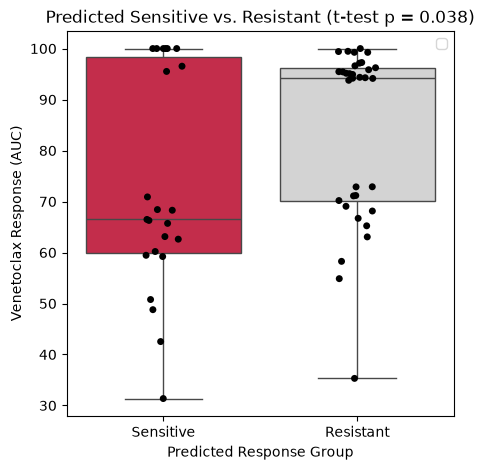

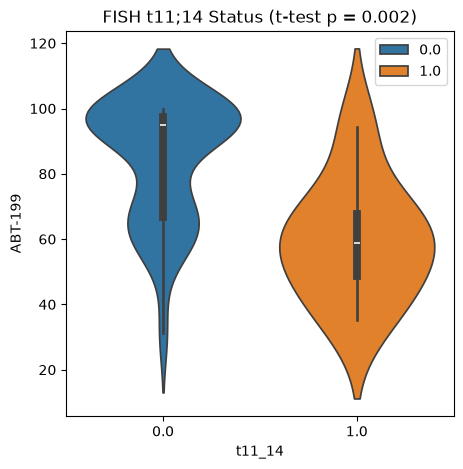

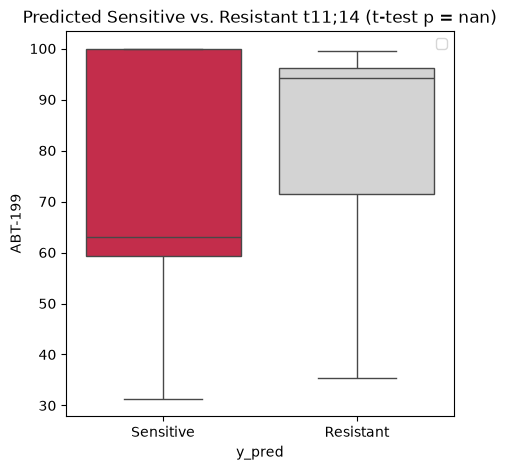

In [9]:
pipeline_results_dir = fig_output + "pipeline_output/"

model_name = "lr_reg"
model_cv_metrics = {}
model_ev_metrics = {}

datasets = harmonize()
mf_ad = datasets["Moffitt"]
dc_ad = datasets["Decampos"]

cv_results= pd.read_csv(f"{pipeline_results_dir}{model_name}_cv_results.csv")
ev_results = pd.read_csv(f"{pipeline_results_dir}{model_name}_ev_results.csv")


# cv violin w predicted classes - and t-test
mf_ad = mf_ad[cv_results['samples']]
mf_ad.obs['y_pred'] = list(cv_results["y_pred"])
mf_ad.obs['y_true'] = list(cv_results['y_true'])

sens_ad = mf_ad[mf_ad.obs['y_pred'] == 1]
res_ad = mf_ad[mf_ad.obs['y_pred'] == 0]
res = ttest_ind(sens_ad.obs["ABT-199"], res_ad.obs["ABT-199"])
p = res.pvalue
model_pval = p

fig, ax = plt.subplots(1,figsize=(5,5))
mf_ad.obs['y_pred'] = ['Sensitive' if y == 1 else 'Resistant' for y in mf_ad.obs['y_pred']]
plt.title(f"Predicted Sensitive vs. Resistant (t-test p = {p:.3f})")
sns.boxplot(pd.DataFrame(mf_ad.obs),y="ABT-199", x="y_pred",hue="y_pred", ax=ax,palette={'Sensitive': "crimson", 'Resistant': 'lightgray'} )
sns.stripplot(pd.DataFrame(mf_ad.obs),y="ABT-199", x="y_pred",hue="y_pred", ax=ax,palette={'Sensitive': "k", 'Resistant': 'k'} )
ax.set_ylabel('Venetoclax Response (AUC)')
ax.set_xlabel("Predicted Response Group")

plt.legend()
plt.savefig(fig_output + "violinplot_cv_pred_groups.png")

# t11_14 violine plot
mf_ad = mf_ad[mf_ad.obs['t11_14'].notna()]

sens_ad = mf_ad[mf_ad.obs['t11_14'] == 1]
res_ad = mf_ad[mf_ad.obs['t11_14'] == 0]

res = ttest_ind(sens_ad.obs["ABT-199"], res_ad.obs["ABT-199"])
p = res.pvalue
t11_14_pval = p

fig, ax = plt.subplots(1,figsize=(5,5))

plt.title(f"FISH t11;14 Status (t-test p = {p:.3f})")

sns.violinplot(pd.DataFrame(mf_ad.obs),y="ABT-199", x="t11_14",hue="t11_14", ax=ax)
plt.legend()
plt.savefig(fig_output + "violinplot_moffitt_t11_14.png")


# show violin plot of predicted sens vs res and t11;14 - I want to show the two p values over each side

#fig, ax = plt.subplots(1,figsize=(5,5))
#mf_ad.obs['t11_14'] = mf_ad.obs['t11_14'].astype(int)
#mf_ad = mf_ad[mf_ad.obs['t11_14'] == 1]
#plt.title(f"FISH vs. Model")

'''
mf_ad.obs = mf_ad.obs.sort_values(by='t11_14')

mf_ad.obs['t11_14'] = ['t11;14 +' if y == 1 else 't11;14 -' for y in mf_ad.obs['t11_14']]
#sns.boxplot(pd.DataFrame(mf_ad.obs), y='ABT-199', x='t11_14', hue='t11_14', ax=ax, palette={'t11;14 +': 'crimson', "t11;14 -": "lightgray"}, linecolor='k', linewidth=1.5)
#starbars.draw_annotation([('t11;14 +', 't11;14 -', f"p = {t11_14_pval:.4f}")])

mf_ad.obs = mf_ad.obs.sort_values(by='y_pred')


sns.boxplot(pd.DataFrame(mf_ad.obs), y='ABT-199', x='y_pred', hue='y_pred', ax=ax, palette={'Sensitive': "crimson", 'Resistant': 'lightgray'}, linecolor='k', linewidth=1.5)

starbars.draw_annotation([('Sensitive', 'Resistant', f"p = {model_pval:.4f}")])

ax.set_xlabel("Label")
plt.legend()
plt.savefig(fig_output + "compare_FISH_model_drug_response.png")
'''

fig, ax = plt.subplots(1,figsize=(5,5))


#mf_ad = mf_ad[mf_ad.obs['t11_14'] == 1]
df = pd.DataFrame(mf_ad.obs)

#df = df[df['t11_14'] == 't11;14 +']

sens_patients = df[df['y_pred'] == 1].index
res_patients = df[df['y_pred'] == 0].index

#print(sens_patients)
res = ttest_ind(df.loc[sens_patients]["ABT-199"], df.loc[res_patients]["ABT-199"])
p = res.pvalue
#print(p)


plt.title(f"Predicted Sensitive vs. Resistant t11;14 (t-test p = {p:.3f})")
sns.boxplot(pd.DataFrame(mf_ad.obs),y="ABT-199", x="y_pred",hue="y_pred", ax=ax,palette={'Sensitive': "crimson", 'Resistant': 'lightgray'} )
plt.legend()
#plt.savefig(fig_output + "violinplot_cv_pred_groups.png")


/tmp/ipykernel_5242/3364655015.py:14: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  test = ttest_ind(obs_df[obs_df['category'] == "Sensitive"]['ABT-199'], obs_df[obs_df['category'] == "t11;14 +"]['ABT-199'])


TypeError: unsupported operand type(s) for -: 'str' and 'str'

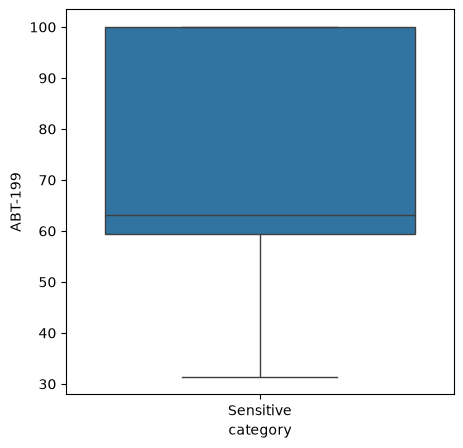

In [10]:
fig, ax = plt.subplots(1, figsize=(5,5))

obs_df = pd.DataFrame(mf_ad.obs)


category = ['Sensitive' if obs_df.loc[y]['y_pred'] == "Sensitive" else 't11;14 +' if obs_df.loc[y]['t11_14'] == "t11;14 +" else None for y in obs_df.index]
samples = [y if obs_df.loc[y]['y_pred'] == "Sensitive" else y if obs_df.loc[y]['t11_14'] == "t11;14 +" else None for y in obs_df.index]
samples = [y for y in samples if y is not None ]
category = [y for y in category if y is not None]

obs_df = obs_df.loc[samples]
obs_df['category'] = category

test = ttest_ind(obs_df[obs_df['category'] == "Sensitive"]['ABT-199'], obs_df[obs_df['category'] == "t11;14 +"]['ABT-199'])
annotation = ('Sensitive', "t11;14 +", f"p val = {test.pvalue:3E}")


sns.boxplot(obs_df, y='ABT-199', x='category', hue='category')
starbars.draw_annotation([annotation])

/tmp/ipykernel_39961/1214996558.py:14: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  test = ttest_ind(obs_df[obs_df['category'] == "Resistant"]['ABT-199'], obs_df[obs_df['category'] == "t11;14 -"]['ABT-199'])


TypeError: unsupported operand type(s) for -: 'str' and 'str'

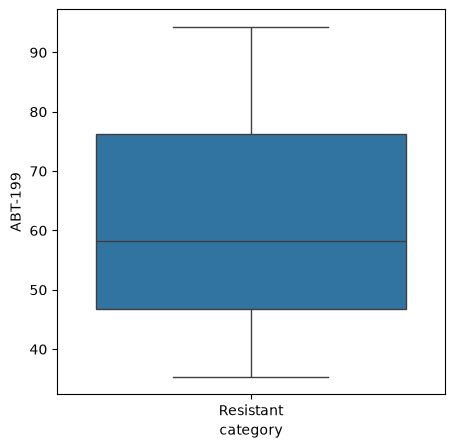

In [ ]:
fig, ax = plt.subplots(1, figsize=(5,5))

obs_df = pd.DataFrame(mf_ad.obs)


category = ['Resistant' if obs_df.loc[y]['y_pred'] == "Resistant" else 't11;14 -' if obs_df.loc[y]['t11_14'] == "t11;14 -" else None for y in obs_df.index]
samples = [y if obs_df.loc[y]['y_pred'] == "Resistant" else y if obs_df.loc[y]['t11_14'] == "t11;14 -" else None for y in obs_df.index]
samples = [y for y in samples if y is not None ]
category = [y for y in category if y is not None]

obs_df = obs_df.loc[samples]
obs_df['category'] = category

test = ttest_ind(obs_df[obs_df['category'] == "Resistant"]['ABT-199'], obs_df[obs_df['category'] == "t11;14 -"]['ABT-199'])
annotation = ('Resistant', "t11;14 -", f"p val = {test.pvalue:3E}")


sns.boxplot(obs_df, y='ABT-199', x='category', hue='category')
starbars.draw_annotation([annotation])

/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!
DeCampos Annotated data found!
Number of Harmonized Genes: 18680


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/tmp/ipykernel_91423/3687330282.py:14: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  mf_ad.obs['y_pred'] = list(cv_results["y_pred"])
/tmp/ipykernel_91423/3687330282.py:26: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  mf_ad.obs['y_pred'] = ['Sensitive' if y == 1 else 'Resistant' for y in mf_ad.obs['y_pred']]
/tmp/ipykernel_91423/3687330282.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


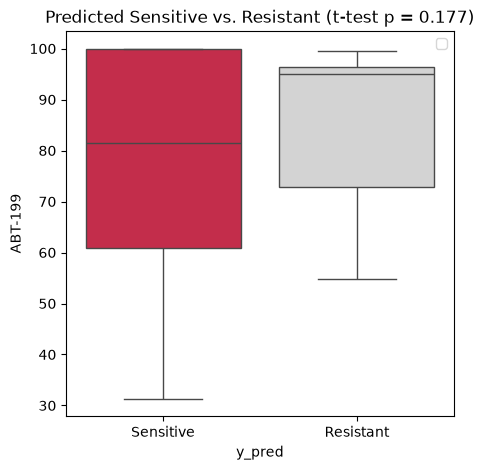

In [ ]:
pipeline_results_dir = fig_output + "pipeline_output/"

model_name = "lr_reg"


datasets = harmonize()
mf_ad = datasets["Moffitt"]

cv_results= pd.read_csv(f"{pipeline_results_dir}{model_name}_cv_results.csv")


# cv violin w predicted classes - and t-test
mf_ad = mf_ad[cv_results['samples']]
mf_ad.obs['y_pred'] = list(cv_results["y_pred"])
mf_ad.obs['y_true'] = list(cv_results['y_true'])

mf_ad = mf_ad[(mf_ad.obs['t11_14'].notna()) & ( mf_ad.obs['t11_14'] == 0)]

sens_ad = mf_ad[mf_ad.obs['y_pred'] == 1]
res_ad = mf_ad[mf_ad.obs['y_pred'] == 0]
res = ttest_ind(sens_ad.obs["ABT-199"], res_ad.obs["ABT-199"])
p = res.pvalue
model_pval = p

fig, ax = plt.subplots(1,figsize=(5,5))
mf_ad.obs['y_pred'] = ['Sensitive' if y == 1 else 'Resistant' for y in mf_ad.obs['y_pred']]
plt.title(f"Predicted Sensitive vs. Resistant (t-test p = {p:.3f})")
sns.boxplot(pd.DataFrame(mf_ad.obs),y="ABT-199", x="y_pred",hue="y_pred", ax=ax,palette={'Sensitive': "crimson", 'Resistant': 'lightgray'} )
plt.legend()
#plt.savefig(fig_output + "violinplot_cv_pred_groups.png")




/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


Moffitt Annotated data found!
CoMMpass Annotated data found!
DeCampos Annotated data found!
Number of Harmonized Genes: 18680


/usr/lib/python3.14/functools.py:982: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)
/tmp/ipykernel_91423/1307344594.py:14: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  dc_ad.obs['y_pred'] = list(ev_results["y_pred"])
/tmp/ipykernel_91423/1307344594.py:21: SmallSampleWarning: One or more sample arguments is too small; all returned values will be NaN. See documentation for sample size requirements.
  res = ttest_ind(sens_ad.obs["ABT-199"], res_ad.obs["ABT-199"])
/tmp/ipykernel_91423/1307344594.py:29: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


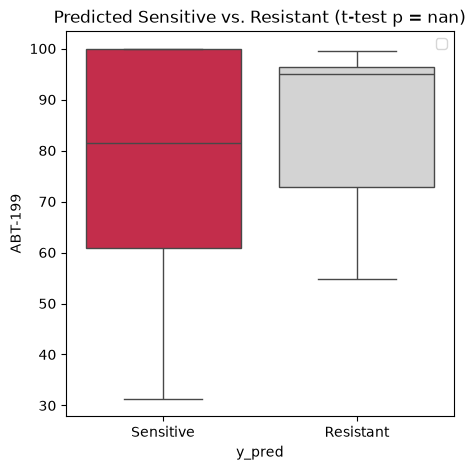

In [ ]:
pipeline_results_dir = fig_output + "pipeline_output/"

model_name = "lr_reg"


datasets = harmonize()
dc_ad = datasets["Decampos"]

ev_results= pd.read_csv(f"{pipeline_results_dir}{model_name}_ev_results.csv")


# cv violin w predicted classes - and t-test
dc_ad = dc_ad[ev_results['samples']]
dc_ad.obs['y_pred'] = list(ev_results["y_pred"])
dc_ad.obs['y_true'] = list(ev_results['y_true'])

#mf_ad = mf_ad[(mf_ad.obs['t11_14'].notna()) & ( mf_ad.obs['t11_14'] == 0)]

sens_ad = dc_ad[dc_ad.obs['y_pred'] == 1]
res_ad = dc_ad[dc_ad.obs['y_pred'] == 0]
res = ttest_ind(sens_ad.obs["ABT-199"], res_ad.obs["ABT-199"])
p = res.pvalue
model_pval = p

fig, ax = plt.subplots(1,figsize=(5,5))
dc_ad.obs['y_pred'] = ['Sensitive' if y == 1 else 'Resistant' for y in dc_ad.obs['y_pred']]
plt.title(f"Predicted Sensitive vs. Resistant (t-test p = {p:.3f})")
sns.boxplot(pd.DataFrame(mf_ad.obs),y="ABT-199", x="y_pred",hue="y_pred", ax=ax,palette={'Sensitive': "crimson", 'Resistant': 'lightgray'} )
plt.legend()
#plt.savefig(fig_output + "violinplot_cv_pred_groups.png")
